In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pysr import PySRRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("mill.csv")
df_clean = df.dropna(subset=["VB"]).copy()

df

,Unnamed: 0,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,row_0,1,1,0.00,2,1.5,0.5,1,-0.017090,0.625000,0.078125,0.314941,0.087280,0.103760
1,row_1,1,2,NaN,4,1.5,0.5,1,0.307617,0.668945,0.075684,0.301514,0.086670,0.099487
2,row_2,1,3,NaN,6,1.5,0.5,1,-0.725098,0.913086,0.083008,0.295410,0.092773,0.104980
3,row_3,1,4,0.11,7,1.5,0.5,1,0.112305,0.131836,0.083008,0.316162,0.112915,0.139771
4,row_4,1,5,NaN,11,1.5,0.5,1,-0.122070,0.449219,0.107422,0.284424,0.095825,0.110474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162,row_162,16,2,NaN,2,1.5,0.5,2,-0.583496,1.308594,0.063477,0.330811,0.093994,0.109253
163,row_163,16,3,0.24,3,1.5,0.5,2,-0.200195,1.406250,0.065918,0.279541,0.114746,0.139771
164,row_164,16,4,NaN,4,1.5,0.5,2,0.244141,1.328125,0.063477,0.290527,0.101318,0.117798
165,row_165,16,5,0.40,6,1.5,0.5,2,-0.205078,1.381836,0.068359,0.289307,0.098877,0.114746


In [4]:
df_clean["is_steel"] = (df_clean["material"] == 2).astype(float)

y = df_clean["VB"]
groups = df_clean["case"]

In [5]:
cols_to_drop = ["Unnamed: 0", "VB", "case", "run", "material"]
X = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])

In [6]:
df

,Unnamed: 0,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,row_0,1,1,0.00,2,1.5,0.5,1,-0.017090,0.625000,0.078125,0.314941,0.087280,0.103760
1,row_1,1,2,NaN,4,1.5,0.5,1,0.307617,0.668945,0.075684,0.301514,0.086670,0.099487
2,row_2,1,3,NaN,6,1.5,0.5,1,-0.725098,0.913086,0.083008,0.295410,0.092773,0.104980
3,row_3,1,4,0.11,7,1.5,0.5,1,0.112305,0.131836,0.083008,0.316162,0.112915,0.139771
4,row_4,1,5,NaN,11,1.5,0.5,1,-0.122070,0.449219,0.107422,0.284424,0.095825,0.110474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162,row_162,16,2,NaN,2,1.5,0.5,2,-0.583496,1.308594,0.063477,0.330811,0.093994,0.109253
163,row_163,16,3,0.24,3,1.5,0.5,2,-0.200195,1.406250,0.065918,0.279541,0.114746,0.139771
164,row_164,16,4,NaN,4,1.5,0.5,2,0.244141,1.328125,0.063477,0.290527,0.101318,0.117798
165,row_165,16,5,0.40,6,1.5,0.5,2,-0.205078,1.381836,0.068359,0.289307,0.098877,0.114746


In [7]:
X.isna().sum().sum() == 0, f"Remaining NaNs found:\n{X.isna().sum()}"
print(f"Clean dataset shape: {X.shape} across {groups.nunique()} cases")
print("Features used:", list(X.columns))

Clean dataset shape: (146, 10) across 16 cases
Features used: ['time', 'DOC', 'feed', 'smcAC', 'smcDC', 'vib_table', 'vib_spindle', 'AE_table', 'AE_spindle', 'is_steel']


In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

Train samples: 113 | Test samples: 33


In [9]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

In [10]:
pysr_model = PySRRegressor(
    niterations=100,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "abs", "exp"],
    nested_constraints={
        "exp": {"exp": 0, "square": 0},
        "square": {"square": 0},
    },
    maxsize=20,
    parsimony=0.0032,
    elementwise_loss="loss(prediction, target) = (prediction - target)^2",
    random_state=42,
    deterministic=True,
    parallelism="serial",
)
pysr_model.fit(X_train, y_train)
pysr_preds = pysr_model.predict(X_test)

Compiling Julia backend...


In [11]:
results = pd.DataFrame([
    {
        "Model": "RandomForestRegressor",
        "R2": r2_score(y_test, rf_preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, rf_preds)),
        "MAE": mean_absolute_error(y_test, rf_preds),
    },
    {
        "Model": "PySR (Best Selected)",
        "R2": r2_score(y_test, pysr_preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, pysr_preds)),
        "MAE": mean_absolute_error(y_test, pysr_preds),
    },
])
print("\n--- Hold-Out Test Metrics ---")
print(results.round(4).to_string(index=False))

print("\n--- PySR Pareto Front (Complexity vs. Loss) ---")
print(pysr_model.equations_[["complexity", "loss", "score", "sympy_format"]].to_string(index=False))

print("\n--- Random Forest Feature Importances ---")
rf_imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(rf_imp.round(4))


--- Hold-Out Test Metrics ---
                Model     R2   RMSE    MAE
RandomForestRegressor 0.8311 0.0687 0.0551
 PySR (Best Selected) 0.5999 0.1057 0.0780

--- PySR Pareto Front (Complexity vs. Loss) ---
 complexity     loss        score                                                                                          sympy_format
          1 0.078498 0.000000e+00                                                                                     0.347610320000000
          3 0.074749 2.446925e-02                                                                                     time*0.0095175095
          4 0.073611 1.533775e-02                                                                     0.0276771036054969/vib_spindle**2
          5 0.059048 2.204435e-01                                                                        time*0.0056861653 + 0.18945542
          6 0.024808 8.671819e-01                                                                        time*e

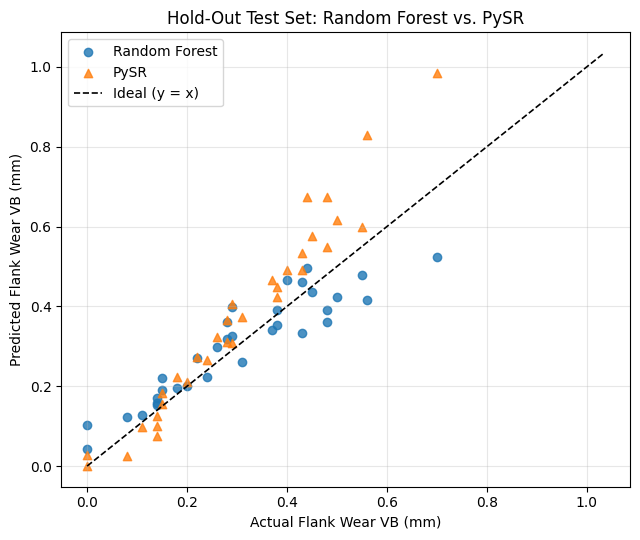


--- 5-Fold GroupKFold Results ---
 Fold  RF_R2  PySR_R2  RF_RMSE  PySR_RMSE                                                                  Best_Equation
    1 0.5706   0.8803   0.1388     0.0733 (DOC + feed)*(time + 4.362445)*(is_steel*time*feed*0.002051319 + 0.0057320455)
    2 0.4774   0.8746   0.1716     0.0840                          time*(DOC + feed)*(is_steel + 0.31753898)*0.020035127
    3 0.5063   0.8879   0.2573     0.1226                          time*(-(-0.008464717)*DOC + is_steel*feed*0.07111647)
    4 0.7616   0.8584   0.0974     0.0751                time*0.015562134*(is_steel + 0.29325953)*(DOC + feed*2.4115486)
    5 0.7482   0.6786   0.0984     0.1111                          exp(feed)*time*(DOC*0.3660341 + is_steel)*0.017481813

Mean CV Scores:
RF_R2        0.6128
PySR_R2      0.8360
RF_RMSE      0.1527
PySR_RMSE    0.0932
dtype: float64


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, rf_preds, alpha=0.8, label="Random Forest", marker="o")
ax.scatter(y_test, pysr_preds, alpha=0.8, label="PySR", marker="^")
lims = [0, max(y_test.max(), rf_preds.max(), pysr_preds.max()) * 1.05]
ax.plot(lims, lims, "k--", lw=1.2, label="Ideal (y = x)")
ax.set_xlabel("Actual Flank Wear VB (mm)")
ax.set_ylabel("Predicted Flank Wear VB (mm)")
ax.set_title("Hold-Out Test Set: Random Forest vs. PySR")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

gkf = GroupKFold(n_splits=5)
cv_results = []

for fold, (tr_idx, te_idx) in enumerate(gkf.split(X, y, groups=groups), 1):
    X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
    y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

    rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_tr, y_tr)
    rf_p = rf.predict(X_te)

    sr = PySRRegressor(
        niterations=100,
        binary_operators=["+", "-", "*", "/"],
        unary_operators=["square", "abs", "exp"],
        nested_constraints={"exp": {"exp": 0, "square": 0}, "square": {"square": 0}},
        maxsize=20,
        parsimony=0.0032,
        elementwise_loss="loss(prediction, target) = (prediction - target)^2",
        random_state=42,
        deterministic=True,
        parallelism="serial",
        verbosity=0,
    ).fit(X_tr, y_tr)
    sr_p = sr.predict(X_te)

    cv_results.append({
        "Fold": fold,
        "RF_R2": r2_score(y_te, rf_p),
        "PySR_R2": r2_score(y_te, sr_p),
        "RF_RMSE": np.sqrt(mean_squared_error(y_te, rf_p)),
        "PySR_RMSE": np.sqrt(mean_squared_error(y_te, sr_p)),
        "Best_Equation": str(sr.sympy()),
    })

cv_df = pd.DataFrame(cv_results)
print("\n--- 5-Fold GroupKFold Results ---")
print(cv_df.round(4).to_string(index=False))
print("\nMean CV Scores:")
print(cv_df[["RF_R2", "PySR_R2", "RF_RMSE", "PySR_RMSE"]].mean().round(4))